In [32]:
import matplotlib.pyplot as plt
import movingpandas as mpd
import geopandas
import shapely as shp
import seaborn as sns
import pandas as pd

import warnings
from movingpandas.unit_utils import MissingCRSWarning
warnings.filterwarnings("ignore", category=MissingCRSWarning)

In [2]:
df = pd.read_parquet('../../data/prepared/baseline/dataset_raw_baseline.parquet')

In [3]:
df['MMSI'].nunique()

3020

In [4]:
df['day'] = df['# Timestamp'].dt.date

In [5]:
from datetime import timedelta

In [6]:
mmsis_days_to_drop = []

for (mmsi, day), df_mmsi in df.groupby(['MMSI', 'day']):

    if df_mmsi['# Timestamp'].diff(1).max() > timedelta(minutes=120):
        print( df_mmsi['# Timestamp'].diff(1).max() )

<Axes: >

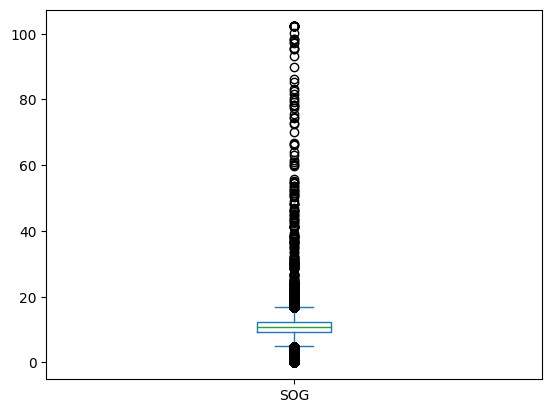

In [7]:
df['SOG'].plot.box()

In [8]:
df.columns

Index(['# Timestamp', 'MMSI', 'Latitude', 'Longitude', 'Navigational status',
       'ROT', 'SOG', 'COG', 'Heading', 'Ship type', 'Cargo type', 'Width',
       'Length', 'date_diff', 'dLat/dt', 'dLong/dt', 'Latitude_next',
       'Longitude_next', 'distance', 'day'],
      dtype='object')

[]

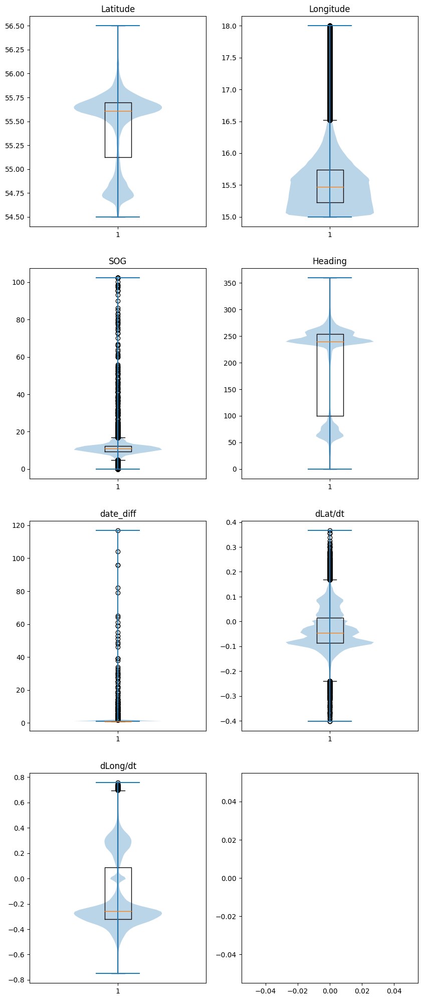

In [15]:
fig, axs = plt.subplots(nrows=4, ncols=2, figsize=(10, 25))

columns = ['Latitude', 'Longitude', 'SOG', 'Heading', 'date_diff', 'dLat/dt', 'dLong/dt']
df_subset = df[columns]

for ix, ax in enumerate(axs.ravel()):

    if ix >= len(columns):
        continue

    if columns[ix] != 'date_diff':
        vals = df_subset[ columns[ix] ]
    else:
        vals = df_subset[ columns[ix] ]\
            .fillna(1)

    ax.boxplot( vals )
    ax.violinplot( vals )
    ax.set_title( columns[ix] )

plt.plot()

https://movingpandas.github.io/movingpandas-website/2-analysis-examples/ship-data.html

In [25]:
# Source - https://stackoverflow.com/q/61733165
# Posted by Andy Thompson
# Retrieved 2026-06-17, License - CC BY-SA 4.0

gdf = geopandas.GeoDataFrame(df, geometry=geopandas.points_from_xy(df.Longitude, df.Latitude))

In [50]:
import folium

In [92]:
m = folium.Map(location=[55, 16.5], zoom_start=7, tiles="Cartodb PositronNoLabels")

for (mmsi, day), df_mmsi in df.groupby(['MMSI', 'day']):
    coord_list = df_mmsi.apply(
        lambda row: [ row['Latitude'], row['Longitude'] ],
        axis='columns'
    )\
        .tolist()

    if len(coord_list) < 10:
        continue

    folium.PolyLine(
        coord_list,
        opacity=0.15,
        weight=1
    ).add_to(m)

folium.Polygon([
    [54.5, 15.0],
    [56.5, 15.0],
    [56.5, 18.0],
    [54.5, 18.0],
    [54.5, 15.0],
], color='black').add_to(m)

In [103]:
df_yipeng = pd.read_csv('../../data/414270000_20241118_sample(in).csv')
df_yipeng.drop_duplicates(subset='static_timestamp', inplace=True)

coord_list = df_yipeng.apply(
    lambda row: [ row['latitude'], row['longitude'] ],
    axis='columns'
)\
    .tolist()

folium.PolyLine(
    coord_list,
    weight=5,
    color='red'
).add_to(m)

In [104]:
m

{'bodies': [<matplotlib.collections.PolyCollection at 0x7f602b7987c0>],
 'cmaxes': <matplotlib.collections.LineCollection at 0x7f603040cd30>,
 'cmins': <matplotlib.collections.LineCollection at 0x7f602b798c40>,
 'cbars': <matplotlib.collections.LineCollection at 0x7f602b798fa0>}

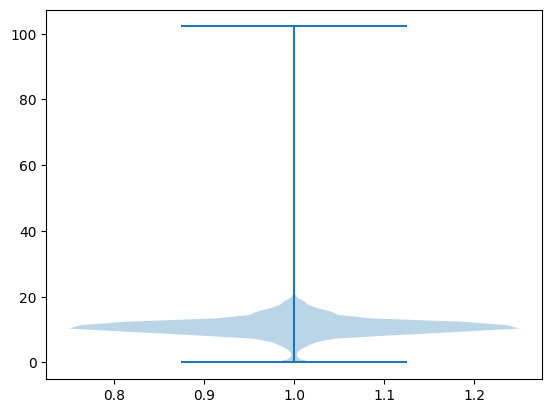

In [107]:
plt.violinplot( df['SOG'].values )

In [109]:
df_subset = df[df['SOG'] > 25]